# Week 05 Friday · Regularization, step by step
**IIT414W · Friday 9 October 2026 · 11:10–13:40 · digital pair activity · v2**

**Goal:** explain what Ridge/L2 and Lasso/L1 change, compare their validation errors, and defend one choice.

| What you do | Why | What you finish | When / where |
|---|---|---|---|
| Work in pairs: predict, run/read, compare | Connect model settings to evidence | Answer cells A–D in this notebook | Save and show your teacher by 13:35 |
| Reflect individually | Identify what you understand or need to revisit | Two complete English sentences | Submit the Canvas exit ticket by 13:40 |

**Nothing to print.** No separate worksheet and no notebook upload for this formative activity. Lab 2 has its own Canvas submission, due today at 11:10.

**How to answer:** double-click an ANSWER cell, replace each `[write here]`, press Shift+Enter, and save. Add both names in A. Use short English or Spanish answers in A–D. The exit ticket is individual and uses English sentence frames. Spelling and grammar are not graded.

**How to use the code:** run cells from top to bottom. Read the comments and outputs; you do not need to recreate the helper function. If Python is unavailable, use the saved outputs and type A–D in a text document, then show it on screen. The teacher will announce one step at a time.

**Route:** setup → concepts → shared pipeline → break 12:25–12:40 → Ridge → Lasso → decision → Canvas ticket.

## 1 · The prediction problem · 11:20–11:40
We predict **pit-stop duration in seconds**, using information available **before the stop**. Each row is one synthetic stop. The CSV has 192 rows across 12 weekends. It is a teaching dataset, not evidence about real F1 performance.

| Column | Meaning in this teaching example | Use |
|---|---|---|
| `weekend` | Time order of the event | Split the data only |
| `lap_number` | Lap of the planned stop | Numeric input |
| `air_temp_c` | Air temperature in degrees Celsius | Numeric input |
| `crew_practice_s` | Prior crew-practice time in seconds | Numeric input |
| `compound` | Tyre compound planned for the stop | Category input |
| `traffic_estimate` | Pre-stop traffic estimate | Category input |
| `pit_duration_s` | Duration we want to predict | Target, never an input |
| `incident_report_after_stop` | Information recorded after the stop | Exclude: unavailable at prediction time |

**Train = learn:** weekends 1–8. Fit preprocessing and model here.  
**Validation = choose:** weekends 9–10. Compare settings here, without refitting preprocessing.  
**Reserved test = final evaluation:** weekends 11–12. Keep untouched throughout this lesson.

A Pipeline applies the preprocessing and model together. **You still choose the time split yourself.**

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

data = pd.read_csv(Path('w05_pit_stops_SYNTHETIC.csv'))
features = ['lap_number', 'air_temp_c', 'crew_practice_s', 'compound', 'traffic_estimate']
target = 'pit_duration_s'
train = data.loc[data.weekend <= 8].copy()
valid = data.loc[data.weekend.between(9, 10)].copy()
reserved_test = data.loc[data.weekend >= 11].copy()  # Count only. Never score today.
X_train, y_train = train[features], train[target]
X_valid, y_valid = valid[features], valid[target]
print('train / validation / reserved test:', len(train), len(valid), len(reserved_test))
print('weekends: 1–8 fit | 9–10 compare | 11–12 untouched')
print('pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)
print('\nFirst three training rows:')
print(train[features + [target]].head(3).to_string(index=False))

train / validation / reserved test: 128 32 32
weekends: 1–8 fit | 9–10 compare | 11–12 untouched
pandas: 2.3.1 | scikit-learn: 1.8.0

First three training rows:
 lap_number  air_temp_c  crew_practice_s compound traffic_estimate  pit_duration_s
         43        14.3             2.86   medium             high            2.63
         44        22.3             2.58   medium              low            2.12
         32        19.1              NaN   medium             high            4.15


### ANSWER A · Data and time · 3 minutes
**Names:** [write here]
1. The weekends used by `.fit(...)` are [write here].
2. The weekends used to choose alpha are [write here].
3. Exclude [write here] because it is known [before / after] the stop.

**Done when:** you can point to the fitting rows and explain one excluded column. Keep the target separate from the inputs.

## 2 · Coefficients, errors and penalties · 11:40–12:00
### A coefficient changes the prediction
A linear model adds an intercept and a contribution from each input. For illustration only:

`predicted seconds = 2.5 + 0.2 × z`

Here `z` is a standardized input: 0 means the training average; 1 means one training standard deviation above it. At `z = 1`, the prediction is **2.7 s**. If that coefficient shrinks from 0.2 to 0.05 and the intercept stays fixed for this illustration, the prediction becomes **2.55 s**. The model responds less strongly to that input. In an actual fit, the other coefficients and intercept may also change.

### MAE tells us the size of the miss
Actual durations `[2.0, 3.0]` and predictions `[2.2, 2.6]` give absolute errors `[0.2, 0.4]`. Their mean is **0.3 seconds**. Lower MAE means smaller average errors. It is not a percentage or accuracy score.

### Why add a penalty?
A flexible fit can react too strongly to noise or overlapping inputs. Regularization encourages smaller coefficients, which can help on new data. Too much shrinkage can remove useful signal and worsen predictions (**underfitting**). Improvement is something we check, not assume.

| Model | Training penalty | What to watch |
|---|---|---|
| Ordinary least squares (OLS) | None | Reference linear model |
| Ridge / L2 | Sum of squared coefficients | Overall coefficient size decreases as the penalty strengthens |
| Lasso / L1 | Sum of absolute coefficients | Some coefficients can become exactly zero |

**Alpha controls penalty strength within a family.** It is a setting we choose, not a coefficient learned by fitting. Ridge and Lasso scale their training objectives differently: the same alpha number does not mean the same strength across families. They train with squared prediction error; today we evaluate with MAE.

Numeric inputs are standardized inside the pipeline so differences in units do not dominate the penalty. Categorical inputs become 0/1 columns. One original category input can therefore produce several coefficients. A zero coefficient means no contribution from that encoded column in this fitted model; it does not prove the original feature is useless in general.

### ANSWER B · Predict before running · 2 minutes
1. Ridge uses [L1 / L2]; Lasso uses [L1 / L2].
2. My prediction: with very strong regularization, coefficient size will [increase / decrease], but validation error [must improve / could worsen].

**Do this before the Ridge and Lasso tables.** Keep your original prediction, then compare it with what happens.

**Optional arithmetic:** coefficients `[2, -1, 0.5]` have L1 penalty `2 + 1 + 0.5 = 3.5` and L2 penalty `4 + 1 + 0.25 = 5.25`. You do not need to derive the optimization algorithm.

## 3 · One visible fit, then a reusable comparison · 12:00–12:25
**Read these three actions:**
1. Create a pipeline with the same preprocessing for every model.
2. Fit on `X_train, y_train` only. The imputers, scaler and encoder learn here too.
3. Predict on `X_valid` and measure MAE. Validation never enters `.fit(...)`.

The cell below defines the preprocessing and demonstrates one Ridge fit. You may run it unchanged. The median baseline predicts the training median for every validation row. OLS provides a reference without a regularization penalty.

In [2]:
numeric = ['lap_number', 'air_temp_c', 'crew_practice_s']
categorical = ['compound', 'traffic_estimate']

def make_preparation():
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('fill', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), numeric),
        ('categorical', Pipeline([
            ('fill', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore')),
        ]), categorical),
    ])

# The central three lines: create, fit, evaluate.
ridge_demo = Pipeline([('prepare', make_preparation()), ('regression', Ridge(alpha=1.0))])
ridge_demo.fit(X_train, y_train)
demo_predictions = ridge_demo.predict(X_valid)
print('Ridge alpha=1 validation MAE:', round(mean_absolute_error(y_valid, demo_predictions), 4), 'seconds')


Ridge alpha=1 validation MAE: 0.1152 seconds


### Reusable helper · provided code
`evaluate(name, estimator, alpha)` repeats those same steps and returns a results row and the fitted pipeline. It avoids accidentally using different preprocessing for different models. **Read the `.fit` and `.predict` lines; you are not expected to memorize the function.**

In the output, `zero_coefficients` counts coefficients equal to zero. `coefficient_count` counts the encoded inputs. The median baseline has no feature coefficients, so these fields are blank/NaN. `coefficient_L2_size` is one overall size summary, the square root of the sum of squared coefficients. Read its direction of change within a family; it is not an error score.

In [3]:
def evaluate(name, estimator, alpha=None):
    model = Pipeline([('prepare', make_preparation()), ('regression', estimator)])
    model.fit(X_train, y_train)  # Only weekends 1–8 fit every learned step.
    predictions = model.predict(X_valid)
    coefficients = getattr(model.named_steps['regression'], 'coef_', None)
    return {
        'model': name,
        'alpha': alpha,
        'validation_MAE_s': mean_absolute_error(y_valid, predictions),
        'zero_coefficients': np.nan if coefficients is None else int(np.sum(coefficients == 0)),
        'coefficient_count': np.nan if coefficients is None else len(coefficients),
        'coefficient_L2_size': np.nan if coefficients is None else float(np.linalg.norm(coefficients)),
    }, model

baseline_row, baseline_model = evaluate('Median baseline', DummyRegressor(strategy='median'))
ols_row, ols_model = evaluate('No penalty (OLS)', LinearRegression())
reference_row, reference_model = evaluate('Ridge', Ridge(alpha=1.0), alpha=1.0)
print(pd.DataFrame([baseline_row, ols_row, reference_row]).round(4).to_string(index=False))

           model  alpha  validation_MAE_s  zero_coefficients  coefficient_count  coefficient_L2_size
 Median baseline    NaN            0.1606                NaN                NaN                  NaN
No penalty (OLS)    NaN            0.1156                0.0                9.0               0.3450
           Ridge    1.0            0.1152                0.0                9.0               0.3348


**Read one result:** a validation MAE of about 0.115 s means an average absolute miss of about 115 milliseconds over these 32 validation stops. This is an average, not a guarantee that every prediction is within 0.115 s.

**Quick oral check:** which dataset supplied the median used to fill missing numeric values? Point to the fitting line.

## Break · 12:25–12:40
Save the notebook. Next: compare Ridge, then Lasso. Keep the time split and inputs fixed.

## 4 · Ridge / L2 · 12:40–12:55
**Before running:** recall your prediction in B. Look at alpha 1 and 100.

**After running:** read the `validation_MAE_s` column, then `coefficient_L2_size`. A smaller coefficient size and a smaller MAE are different outcomes. Does stronger shrinkage help prediction here?

In [4]:
ridge_rows = []
for alpha in [0.1, 1.0, 10.0, 100.0]:
    row, _ = evaluate('Ridge', Ridge(alpha=alpha), alpha=alpha)
    ridge_rows.append(row)
ridge_table = pd.DataFrame(ridge_rows)
print(ridge_table[['alpha', 'validation_MAE_s', 'zero_coefficients',
                   'coefficient_count', 'coefficient_L2_size']].round(4).to_string(index=False))

 alpha  validation_MAE_s  zero_coefficients  coefficient_count  coefficient_L2_size
   0.1            0.1155                  0                  9               0.3440
   1.0            0.1152                  0                  9               0.3348
  10.0            0.1157                  0                  9               0.2681
 100.0            0.1399                  0                  9               0.1102


## 5 · Lasso / L1 · 12:55–13:10
**Before running:** predict what happens to the count of zero coefficients when alpha rises.

**After running:** compare alpha 0.001 and 0.1. Read error and zeros together. A model that ignores more columns may lose useful information.

In [5]:
lasso_rows = []
for alpha in [0.001, 0.01, 0.1]:
    row, _ = evaluate('Lasso', Lasso(alpha=alpha, max_iter=20000), alpha=alpha)
    lasso_rows.append(row)
lasso_table = pd.DataFrame(lasso_rows)
print(lasso_table[['alpha', 'validation_MAE_s', 'zero_coefficients',
                   'coefficient_count', 'coefficient_L2_size']].round(4).to_string(index=False))

 alpha  validation_MAE_s  zero_coefficients  coefficient_count  coefficient_L2_size
 0.001            0.1158                  2                  9               0.3490
 0.010            0.1170                  4                  9               0.2959
 0.100            0.1639                  8                  9               0.0466


### ANSWER C · Evidence and interpretation · 5 minutes
Fill this table from the outputs. Then explain the trade-off in one short sentence.

| Setting | Validation MAE (seconds) | Zero coefficients |
|---|---|---|
| Ridge, alpha 1 | [write here] | [write here] |
| Ridge, alpha 100 | [write here] | [write here] |
| Lasso, alpha 0.001 | [write here] | [write here] |
| Lasso, alpha 0.1 | [write here] | [write here] |

1. From Ridge alpha 1 to 100, coefficient size [write here], while validation error [write here].
2. Strong Lasso gives more [write here], but its MAE is [better / worse] than the median baseline.

**Done when:** you have connected a model change to its prediction cost, not just copied a table.

## 6 · Read the two graphs · 13:10–13:20
These are **validation curves over alpha**, not learning curves over training-set size.

1. Choose a panel: Ridge on the left, Lasso on the right.
2. Read the horizontal axis: larger alpha means stronger regularization **in that family**. The axis is logarithmic: equal horizontal steps represent multiplication, not addition.
3. Read the vertical axis: validation MAE in seconds. Lower means a smaller average miss.
4. Compare with the dashed median-baseline line. Points below it beat that baseline on this validation set.

The panels use different alpha values. The lowest tested point is the best observed value among these few settings; it does not prove a universal optimum. The two panels share the MAE scale.

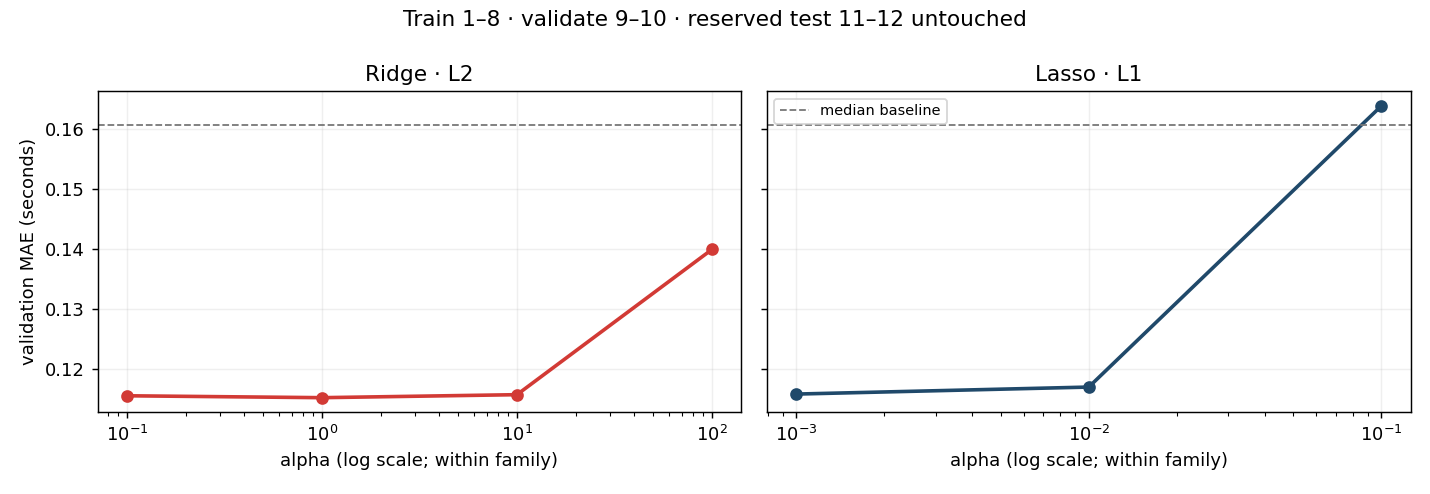

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, table, label, color in [
    (axes[0], ridge_table, 'Ridge · L2', '#d23a35'),
    (axes[1], lasso_table, 'Lasso · L1', '#20496a'),
]:
    ax.plot(table.alpha, table.validation_MAE_s, marker='o', linewidth=2, color=color)
    ax.axhline(baseline_row['validation_MAE_s'], color='#777777', linestyle='--',
               linewidth=1, label='median baseline')
    ax.set_xscale('log')
    ax.set_title(label)
    ax.set_xlabel('alpha (log scale; within family)')
    ax.grid(alpha=0.2)
axes[0].set_ylabel('validation MAE (seconds)')
axes[1].legend(loc='upper left', fontsize=8)
fig.suptitle('Train 1–8 · validate 9–10 · reserved test 11–12 untouched')
fig.tight_layout()
plt.show()

### ANSWER D · Choose and check an AI claim · 13:20–13:35
1. Our choice is [model] with alpha [value, or N/A for OLS]. Its validation MAE is [value] s. We choose it because [one reason about error and/or simplicity].
2. One limitation is [write here].
3. An AI assistant recommends: “Try many alpha values on weekends 11–12 and choose the lowest test MAE.” We [accept / reject] this advice because [write here]. We would choose alpha using [dataset] instead.

**Success criteria:** one setting, one reported number, one defensible reason, one limitation, and correct use of the data split. Different choices can be reasonable. A tiny difference such as 0.0004 s on 32 synthetic stops is weak evidence of superiority. No one needs to claim that regularization always wins.

**At 13:35:** save the notebook and show A–D to your teacher on screen. Each partner gives a 20-second explanation. This is formative feedback, not another graded lab. Keep your saved copy for next week's individual control.

## 7 · Individual Canvas exit ticket · 13:35–13:40
Open [Exit Ticket · Week 5 · Friday](https://udd.instructure.com/courses/81962/assignments/549723) from the Week 5 Friday Canvas page. Submit your own text entry before 13:40. Copy each full sentence and replace the brackets:

1. “In our Ridge comparison, increasing alpha from 1 to 100 made coefficient size [change] and validation MAE [change].”
2. “I would choose alpha using the [name] set and keep the [name] set for the final evaluation because [reason].”

If you are unsure, answer that question with: “I am unsure about [specific point], so I would check [specific next step].” Address both questions with one complete English sentence each. You may consult the notebook. Write your own reflection. Spelling and grammar are not graded. Valid participation counts toward the C2 bonus under the published policy.

**Reference:** [scikit-learn: linear models, Ridge and Lasso](https://scikit-learn.org/stable/modules/linear_model.html).